# Q5–Q6. Contributory Causes, Intersection Controls and Severe Injury

**Course** — CSC17104 · Programming for Data Science
**Group** — Group 14 · Tam Khuyển
**Question owner** — Nguyễn Gia Kiệt (24127195)
**Scope** — Non-ML · 2018–2024 comparison period
**Dataset** — Traffic Accidents, Chicago (Kaggle snapshot)
**Assistance log** — [LLM_USAGE.md](../LLM_USAGE.md)

## Introduction

**Research questions**

- **Q5** — Which groups of primary contributory causes have an unusually high share of crashes with a *severe* injury (fatal or incapacitating)? Does the ranking survive once we account for the type of collision, and under other reasonable analysis choices?
- **Q6** — At intersections, how does the severe-injury share differ between traffic signals, stop signs/flashers and no controls, by daylight versus darkness and by collision type?

**Why these questions matter**

- **Q5** — Enforcement and education campaigns have a limited budget. If a cause group is linked to more severe outcomes *after* accounting for who was hit (pedestrians, cyclists, other vehicles), it is a better target for police enforcement and driver-education programmes than a cause that only looks dangerous because it often involves pedestrians.
- **Q6** — City traffic engineers decide which intersections get signals, stop signs or redesigns. Knowing whether the control type is associated with severity *within the same collision type and lighting* helps separate the effect of the device from the kinds of crashes that happen at each kind of intersection.

**Who uses the answer** — Chicago Department of Transportation (intersection design, lighting), Chicago Police Department (enforcement priorities) and road-safety researchers.

**Criteria used** — Q5: D3 (derived cause and collision groups), D4 (direct standardisation by collision type, within-subgroup rankings), D5 (Wilson intervals, risk ratios), D6 (ranking under other period, outcome and threshold choices). Q6: D2 (pivot tables, hour-of-day profile with a rolling window), D3 (lighting and collision groups), D4 (strata of collision type × lighting), D5 (Wilson intervals, Mantel–Haenszel odds ratios and tests).

**Outcome definition** — `has_severe_injury` from `src/data_loader.py`: at least one fatal or incapacitating injury in the crash. It is rare (about 3.4% of crashes), so every rate below is reported with a 95% confidence interval.

## 1. Setup

The notebook runs in two places:

- **Local (VS Code / Jupyter)** — reads the repository directly and writes figures and tables to `data/processed/q5_q6/` (ignored by Git).
- **Google Colab** — clones the public repository, mounts Google Drive and writes every output to `MyDrive/Traffic-Accidents/q5_q6/`, so the whole team can open the same files.

If the raw CSV does not exist yet, it is extracted from `data/traffic_accidents.zip`.

In [1]:
from pathlib import Path
import subprocess
import sys
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.proportion import proportion_confint

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Tam-Khuyen/Traffic-Accidents.git"

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/Traffic-Accidents")
    if not PROJECT_ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(PROJECT_ROOT)], check=True)
    OUTPUT_DIR = Path("/content/drive/MyDrive/Traffic-Accidents/q5_q6")
else:
    PROJECT_ROOT = Path.cwd()
    if PROJECT_ROOT.name == "notebooks":
        PROJECT_ROOT = PROJECT_ROOT.parent
    OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "q5_q6"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "traffic_accidents.csv"
if not RAW_DATA_PATH.exists():
    RAW_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(PROJECT_ROOT / "data" / "traffic_accidents.zip") as archive:
        archive.extract("traffic_accidents.csv", RAW_DATA_PATH.parent)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_clean

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

print(f"Running in {'Google Colab' if IN_COLAB else 'local Jupyter'}")
print(f"Outputs are saved to: {OUTPUT_DIR}")

Running in local Jupyter
Outputs are saved to: /mnt/e/LTKHDL/Đồ-Án/Git/Traffic-Accidents/data/processed/q5_q6


### Helper functions

Three small functions are reused by both questions:

- `report_rows` prints the row count before and after every filter, as the project requires.
- `rate_table` counts crashes and severe crashes per group and adds the 95% **Wilson** interval. Wilson is used instead of the normal approximation because the rate is close to 0 and some groups are small; the normal interval can then go below 0%.
- `standardized_rate` performs **direct standardisation**: each group's rate inside every stratum (for example, each collision type) is weighted by the stratum mix of the *whole* sample. The result answers "what would this group's severe-injury rate be if it had the same mix of collision types as all crashes?". Strata where a group has no crashes are skipped and the remaining weights are rescaled; `weight_coverage_pct` shows how much of the reference mix was usable.

In [2]:
def report_rows(before, after, step):
    """Print the row count before and after a filtering step."""
    print(f"{step}: {len(before):,} -> {len(after):,} rows ({len(before) - len(after):,} removed)")


def rate_table(data, by, outcome="has_severe_injury"):
    """Crashes, severe crashes, rate (%) and 95% Wilson interval per group."""
    table = (
        data.groupby(by, observed=True)[outcome]
        .agg(crashes="size", severe="sum")
        .reset_index()
    )
    low, high = proportion_confint(table["severe"], table["crashes"], alpha=0.05, method="wilson")
    table["rate_pct"] = 100 * table["severe"] / table["crashes"]
    table["ci_low_pct"] = 100 * low
    table["ci_high_pct"] = 100 * high
    return table


def standardized_rate(data, group_col, strata_cols, outcome="has_severe_injury"):
    """Directly standardised rate (%) of each group, using the whole sample's stratum mix as weights."""
    reference_mix = data.groupby(strata_cols, observed=True).size() / len(data)
    rows = []
    for group, subset in data.groupby(group_col, observed=True):
        stratum_rates = subset.groupby(strata_cols, observed=True)[outcome].mean()
        weights = reference_mix.reindex(stratum_rates.index)
        coverage = weights.sum()
        rows.append(
            {
                group_col: group,
                "std_rate_pct": 100 * (stratum_rates * weights).sum() / coverage,
                "weight_coverage_pct": 100 * coverage,
            }
        )
    return pd.DataFrame(rows)


def save_figure(fig, name):
    """Save a figure to the output folder and show it."""
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the shared cleaned data

`load_clean()` from `src/data_loader.py` is the team's shared preprocessing: it removes 31 exact duplicate rows, parses `crash_date`, converts injury counts to integers and adds `crash_year` and `has_severe_injury`.

The analysis then keeps **2018–2024**, the comparison period used by the whole team: 2013–2017 are incomplete because Chicago moved to electronic crash reports gradually, and 2025 contains only January. The full period is reused later as a robustness check for Q5.

In [3]:
all_years = load_clean(RAW_DATA_PATH)

crashes = all_years[all_years["crash_year"].between(2018, 2024)].copy()
report_rows(all_years, crashes, "Keep 2018-2024")

overall_rate = 100 * crashes["has_severe_injury"].mean()
print(f"Severe-injury crashes in 2018-2024: {crashes['has_severe_injury'].sum():,} "
      f"of {len(crashes):,} ({overall_rate:.2f}%)")

Rows before removing duplicates: 209,306
Rows after removing duplicates: 209,275
Rows removed: 31
Keep 2018-2024: 209,275 -> 181,051 rows (28,224 removed)
Severe-injury crashes in 2018-2024: 6,146 of 181,051 (3.39%)


### Derived collision-type groups (used by Q5 and Q6)

`first_crash_type` has 18 labels and several are tiny (for example `TRAIN` has 5 crashes). They are grouped by **who or what was hit**, which is the main physical driver of injury severity:

| Group | Labels |
|---|---|
| Pedestrian / cyclist | `PEDESTRIAN`, `PEDALCYCLIST` |
| Angle / turning | `ANGLE`, `TURNING` |
| Rear-end / same-direction | `REAR END`, `SIDESWIPE SAME DIRECTION`, `REAR TO FRONT`, `REAR TO SIDE`, `REAR TO REAR` |
| Head-on / opposite-direction | `HEAD ON`, `SIDESWIPE OPPOSITE DIRECTION` |
| Single vehicle / object | `FIXED OBJECT`, `OTHER OBJECT`, `PARKED MOTOR VEHICLE`, `OVERTURNED`, `OTHER NONCOLLISION`, `ANIMAL`, `TRAIN` |

The mapping is checked so that no label is silently left out.

In [4]:
COLLISION_GROUPS = {
    "Pedestrian / cyclist": ["PEDESTRIAN", "PEDALCYCLIST"],
    "Angle / turning": ["ANGLE", "TURNING"],
    "Rear-end / same-direction": [
        "REAR END", "SIDESWIPE SAME DIRECTION", "REAR TO FRONT", "REAR TO SIDE", "REAR TO REAR",
    ],
    "Head-on / opposite-direction": ["HEAD ON", "SIDESWIPE OPPOSITE DIRECTION"],
    "Single vehicle / object": [
        "FIXED OBJECT", "OTHER OBJECT", "PARKED MOTOR VEHICLE", "OVERTURNED",
        "OTHER NONCOLLISION", "ANIMAL", "TRAIN",
    ],
}
collision_lookup = {label: group for group, labels in COLLISION_GROUPS.items() for label in labels}

unmapped = sorted(set(all_years["first_crash_type"]) - set(collision_lookup))
assert not unmapped, f"Unmapped collision types: {unmapped}"

for frame in (all_years, crashes):
    frame["collision_group"] = frame["first_crash_type"].map(collision_lookup)

rate_table(crashes, "collision_group").sort_values("rate_pct", ascending=False).round(2)

,collision_group,crashes,severe,rate_pct,ci_low_pct,ci_high_pct
2,Pedestrian / cyclist,12731,1963,15.42,14.80,16.06
1,Head-on / opposite-direction,3136,143,4.56,3.88,5.35
4,Single vehicle / object,9546,339,3.55,3.20,3.94
0,Angle / turning,102359,3149,3.08,2.97,3.18
3,Rear-end / same-direction,53279,552,1.04,0.95,1.13


Pedestrian and cyclist crashes are far more severe than any vehicle-to-vehicle group. Any comparison of causes or intersection controls therefore has to check whether a difference simply reflects a different share of pedestrian and cyclist crashes. This is the confounder controlled for in both questions.

---
## 3. Q5 — Contributory causes and severe injury

### 3.1 Preprocessing: grouping the 40 cause labels (D3)

`prim_contributory_cause` is the officer's judgement of the main cause. It has 40 labels; 13 of them have fewer than 250 crashes in 2018–2024, which gives very wide intervals. The labels are grouped by the **kind of driver behaviour or condition** they describe:

| Cause group | Labels |
|---|---|
| Signal / sign violation | disregarding traffic signals, stop sign, yield sign, other signs, road markings; turning right on red; passing a stopped school bus |
| Failure to yield | failing to yield right-of-way |
| Speed | failing to reduce speed, exceeding safe speed, exceeding the speed limit |
| Impaired driver | under the influence of alcohol/drugs, had been drinking, physical condition of driver |
| Distraction | distraction inside/outside the vehicle, electronic devices, cell phone use, texting |
| Reckless / wrong way | erratic, reckless, careless or aggressive driving; driving on the wrong side |
| Manoeuvre error | following too closely, improper turning, overtaking, lane usage, backing; driving skills/experience |
| Environment / road | weather, vision obscured, road construction, road defects, evasive action, animal, obstructed crosswalk, bus stop |
| Vehicle equipment | equipment – vehicle condition |
| Other recorded cause | bicycle or motorcycle advancing legally on red |
| Not determined | unable to determine, not applicable |

`Not determined` (about 30% of crashes) is kept as its own group instead of being dropped: dropping it would change the denominator of every share. The ranking question is answered among the ten *recorded* cause groups. **Manoeuvre error** is used as the reference group for risk ratios because it is a large group of ordinary driving mistakes.

In [5]:
CAUSE_GROUPS = {
    "Signal / sign violation": [
        "DISREGARDING TRAFFIC SIGNALS", "DISREGARDING STOP SIGN", "DISREGARDING YIELD SIGN",
        "DISREGARDING OTHER TRAFFIC SIGNS", "DISREGARDING ROAD MARKINGS", "TURNING RIGHT ON RED",
        "PASSING STOPPED SCHOOL BUS",
    ],
    "Failure to yield": ["FAILING TO YIELD RIGHT-OF-WAY"],
    "Speed": [
        "FAILING TO REDUCE SPEED TO AVOID CRASH", "EXCEEDING SAFE SPEED FOR CONDITIONS",
        "EXCEEDING AUTHORIZED SPEED LIMIT",
    ],
    "Impaired driver": [
        "UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN ARREST IS EFFECTED)",
        "HAD BEEN DRINKING (USE WHEN ARREST IS NOT MADE)", "PHYSICAL CONDITION OF DRIVER",
    ],
    "Distraction": [
        "DISTRACTION - FROM INSIDE VEHICLE", "DISTRACTION - FROM OUTSIDE VEHICLE",
        "DISTRACTION - OTHER ELECTRONIC DEVICE (NAVIGATION DEVICE, DVD PLAYER, ETC.)",
        "CELL PHONE USE OTHER THAN TEXTING", "TEXTING",
    ],
    "Reckless / wrong way": [
        "OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELESS, NEGLIGENT OR AGGRESSIVE MANNER",
        "DRIVING ON WRONG SIDE/WRONG WAY",
    ],
    "Manoeuvre error": [
        "FOLLOWING TOO CLOSELY", "IMPROPER TURNING/NO SIGNAL", "IMPROPER OVERTAKING/PASSING",
        "IMPROPER LANE USAGE", "IMPROPER BACKING", "DRIVING SKILLS/KNOWLEDGE/EXPERIENCE",
    ],
    "Environment / road": [
        "WEATHER", "VISION OBSCURED (SIGNS, TREE LIMBS, BUILDINGS, ETC.)",
        "ROAD CONSTRUCTION/MAINTENANCE", "ROAD ENGINEERING/SURFACE/MARKING DEFECTS",
        "EVASIVE ACTION DUE TO ANIMAL, OBJECT, NONMOTORIST", "ANIMAL", "OBSTRUCTED CROSSWALKS",
        "RELATED TO BUS STOP",
    ],
    "Vehicle equipment": ["EQUIPMENT - VEHICLE CONDITION"],
    "Other recorded cause": [
        "BICYCLE ADVANCING LEGALLY ON RED LIGHT", "MOTORCYCLE ADVANCING LEGALLY ON RED LIGHT",
    ],
    "Not determined": ["UNABLE TO DETERMINE", "NOT APPLICABLE"],
}
cause_lookup = {label: group for group, labels in CAUSE_GROUPS.items() for label in labels}

unmapped = sorted(set(all_years["prim_contributory_cause"]) - set(cause_lookup))
assert not unmapped, f"Unmapped causes: {unmapped}"

for frame in (all_years, crashes):
    frame["cause_group"] = frame["prim_contributory_cause"].map(cause_lookup)

REFERENCE_CAUSE = "Manoeuvre error"
EXCLUDED_FROM_RANKING = ["Not determined", "Other recorded cause"]

print(crashes["cause_group"].value_counts().to_string())

cause_group
Not determined             55361
Manoeuvre error            45213
Failure to yield           37544
Signal / sign violation    20846
Speed                       9916
Environment / road          4963
Reckless / wrong way        2735
Distraction                 2056
Impaired driver             1538
Vehicle equipment            847
Other recorded cause          32


`Other recorded cause` has only a few dozen crashes, so it is shown in tables but left out of rankings and charts.

### 3.2 Crude severe-injury rate by cause group (D5)

For each cause group: the severe-injury rate with a 95% Wilson interval, and the **risk ratio** against `Manoeuvre error`. The interval of the risk ratio uses the usual log method, $\log(RR) \pm 1.96\sqrt{1/a - 1/n_1 + 1/c - 1/n_0}$, where $a, n_1$ are the severe crashes and crashes of the group and $c, n_0$ those of the reference.

In [6]:
def add_risk_ratio(table, reference):
    """Risk ratio and 95% CI of every group against the reference group."""
    ref = table.loc[table["cause_group"] == reference].iloc[0]
    a, n1 = table["severe"], table["crashes"]
    c, n0 = ref["severe"], ref["crashes"]
    rr = (a / n1) / (c / n0)
    se = np.sqrt(1 / a - 1 / n1 + 1 / c - 1 / n0)
    table = table.copy()
    table["risk_ratio"] = rr
    table["rr_low"] = np.exp(np.log(rr) - 1.96 * se)
    table["rr_high"] = np.exp(np.log(rr) + 1.96 * se)
    return table


q5_crude = add_risk_ratio(rate_table(crashes, "cause_group"), REFERENCE_CAUSE)
q5_crude = q5_crude.sort_values("rate_pct", ascending=False).reset_index(drop=True)
q5_crude.to_csv(OUTPUT_DIR / "q5_crude_rates.csv", index=False)
q5_crude.round(2)

,cause_group,crashes,severe,rate_pct,ci_low_pct,ci_high_pct,risk_ratio,rr_low,rr_high
0,Other recorded cause,32,6,18.75,8.89,35.31,14.79,7.16,30.57
1,Impaired driver,1538,165,10.73,9.28,12.37,8.47,7.17,9.99
2,Reckless / wrong way,2735,191,6.98,6.09,8.00,5.51,4.70,6.46
3,Signal / sign violation,20846,1188,5.70,5.39,6.02,4.50,4.08,4.96
4,Speed,9916,446,4.50,4.11,4.92,3.55,3.14,4.01
5,Failure to yield,37544,1687,4.49,4.29,4.71,3.55,3.23,3.89
6,Vehicle equipment,847,33,3.90,2.79,5.42,3.07,2.18,4.34
7,Environment / road,4963,185,3.73,3.24,4.29,2.94,2.50,3.46
8,Distraction,2056,62,3.02,2.36,3.85,2.38,1.84,3.08
9,Not determined,55361,1610,2.91,2.77,3.05,2.29,2.09,2.52


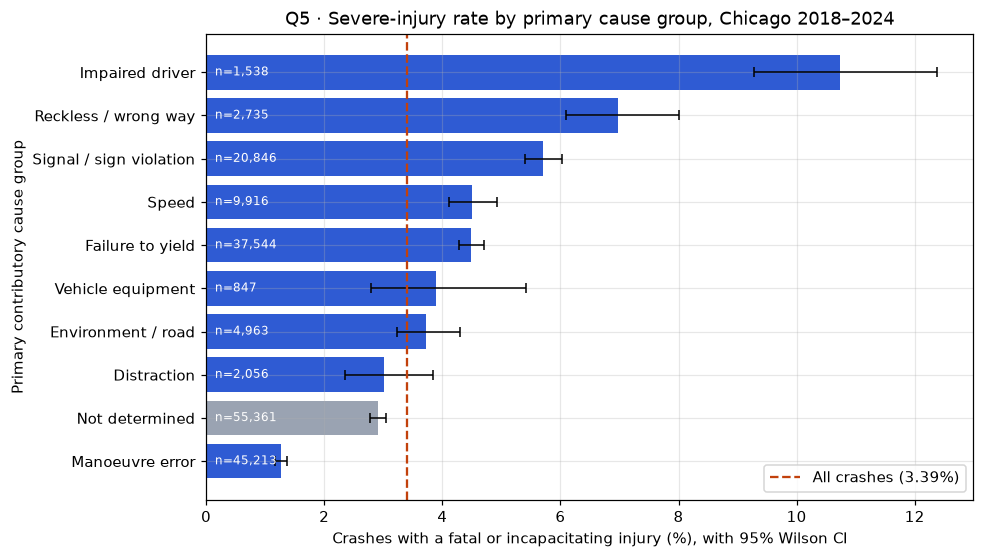

In [7]:
plot_data = q5_crude[~q5_crude["cause_group"].isin(["Other recorded cause"])].sort_values("rate_pct")
colors = ["#9aa3b2" if g == "Not determined" else "#2f5bd3" for g in plot_data["cause_group"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_data["cause_group"], plot_data["rate_pct"], color=colors)
ax.errorbar(
    plot_data["rate_pct"], plot_data["cause_group"],
    xerr=[plot_data["rate_pct"] - plot_data["ci_low_pct"], plot_data["ci_high_pct"] - plot_data["rate_pct"]],
    fmt="none", ecolor="black", capsize=3, linewidth=1,
)
ax.axvline(overall_rate, color="#c2410c", linestyle="--", label=f"All crashes ({overall_rate:.2f}%)")
for y, (rate, n) in enumerate(zip(plot_data["rate_pct"], plot_data["crashes"])):
    ax.text(0.15, y, f"n={n:,}", va="center", ha="left", color="white", fontsize=8)
ax.set_title("Q5 · Severe-injury rate by primary cause group, Chicago 2018–2024")
ax.set_xlabel("Crashes with a fatal or incapacitating injury (%), with 95% Wilson CI")
ax.set_ylabel("Primary contributory cause group")
ax.legend(loc="lower right")
save_figure(fig, "q5_fig1_crude_rate_by_cause")

### 3.3 Is the ranking explained by who was hit? (D4)

A cause can look dangerous simply because it often involves pedestrians or cyclists. The first table shows the share of pedestrian/cyclist crashes in each cause group. Then the severe-injury rate is **directly standardised** to the collision-type mix of all crashes.

In [8]:
collision_mix = (
    pd.crosstab(crashes["cause_group"], crashes["collision_group"], normalize="index") * 100
).round(1)
collision_mix = collision_mix.loc[q5_crude["cause_group"]]
collision_mix

collision_group,Angle / turning,Head-on / opposite-direction,Pedestrian / cyclist,Rear-end / same-direction,Single vehicle / object
cause_group,,,,,
Other recorded cause,12.5,0.0,78.1,9.4,0.0
Impaired driver,29.4,6.8,3.3,33.7,26.9
Reckless / wrong way,43.9,12.9,8.8,21.8,12.6
Signal / sign violation,88.6,1.2,5.5,3.6,1.1
Speed,33.4,1.6,5.1,52.5,7.5
Failure to yield,79.4,1.0,12.3,6.7,0.6
Vehicle equipment,34.6,2.8,1.9,36.8,23.8
Environment / road,44.0,1.7,13.3,23.8,17.2
Distraction,25.5,2.4,7.7,50.6,13.8


In [9]:
q5_std = standardized_rate(crashes, "cause_group", ["collision_group"])
q5_compare = q5_crude[["cause_group", "crashes", "rate_pct", "ci_low_pct", "ci_high_pct", "risk_ratio"]].merge(
    q5_std, on="cause_group", how="left"
)
q5_compare["pct_pedestrian_cyclist"] = q5_compare["cause_group"].map(collision_mix["Pedestrian / cyclist"])

ranked = q5_compare[~q5_compare["cause_group"].isin(EXCLUDED_FROM_RANKING)].copy()
ranked["rank_crude"] = ranked["rate_pct"].rank(ascending=False).astype(int)
ranked["rank_standardized"] = ranked["std_rate_pct"].rank(ascending=False).astype(int)
ranked = ranked.sort_values("rank_standardized").reset_index(drop=True)
ranked.to_csv(OUTPUT_DIR / "q5_crude_vs_standardized.csv", index=False)
ranked.round(2)

,cause_group,crashes,rate_pct,ci_low_pct,ci_high_pct,risk_ratio,std_rate_pct,weight_coverage_pct,pct_pedestrian_cyclist,rank_crude,rank_standardized
0,Impaired driver,1538,10.73,9.28,12.37,8.47,12.64,100.0,3.3,1,1
1,Reckless / wrong way,2735,6.98,6.09,8.00,5.51,6.34,100.0,8.8,2,2
2,Speed,9916,4.50,4.11,4.92,3.55,5.47,100.0,5.1,4,3
3,Signal / sign violation,20846,5.70,5.39,6.02,4.50,5.41,100.0,5.5,3,4
4,Vehicle equipment,847,3.90,2.79,5.42,3.07,5.28,100.0,1.9,6,5
5,Failure to yield,37544,4.49,4.29,4.71,3.55,3.45,100.0,12.3,5,6
6,Distraction,2056,3.02,2.36,3.85,2.38,3.00,100.0,7.7,8,7
7,Environment / road,4963,3.73,3.24,4.29,2.94,2.67,100.0,13.3,7,8
8,Manoeuvre error,45213,1.27,1.17,1.37,1.00,1.90,100.0,1.8,9,9


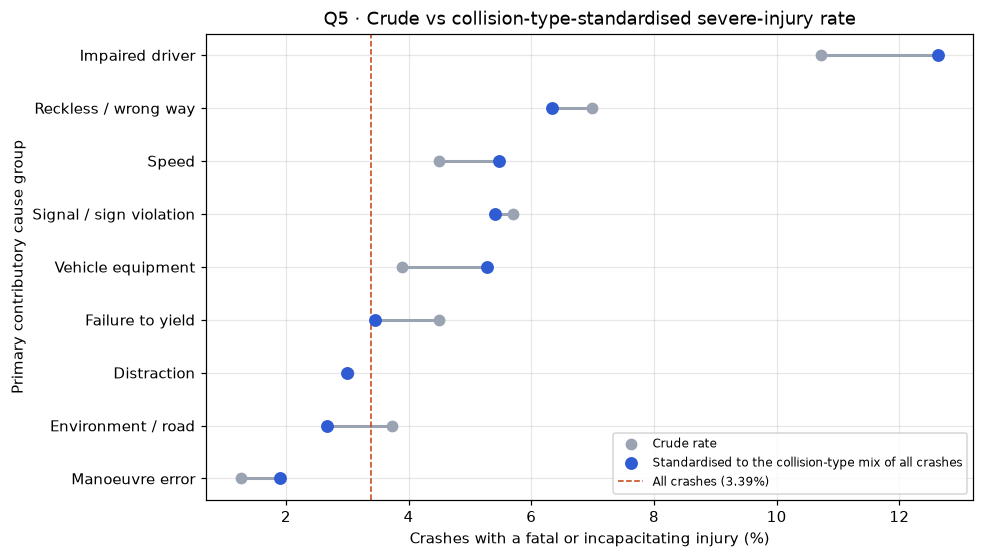

In [10]:
plot_data = ranked.sort_values("std_rate_pct")
y = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hlines(y, plot_data["rate_pct"], plot_data["std_rate_pct"], color="#9aa3b2", linewidth=2)
ax.scatter(plot_data["rate_pct"], y, color="#9aa3b2", s=45, label="Crude rate", zorder=3)
ax.scatter(plot_data["std_rate_pct"], y, color="#2f5bd3", s=55,
           label="Standardised to the collision-type mix of all crashes", zorder=3)
ax.axvline(overall_rate, color="#c2410c", linestyle="--", linewidth=1, label=f"All crashes ({overall_rate:.2f}%)")
ax.set_yticks(y, plot_data["cause_group"])
ax.set_title("Q5 · Crude vs collision-type-standardised severe-injury rate")
ax.set_xlabel("Crashes with a fatal or incapacitating injury (%)")
ax.set_ylabel("Primary contributory cause group")
ax.legend(loc="lower right", fontsize=8)
save_figure(fig, "q5_fig2_crude_vs_standardized")

### 3.4 Ranking inside collision subgroups (D4)

Standardisation gives one number per cause. Here the comparison is done **inside** the two collision groups that matter most: crashes with a pedestrian or cyclist, and crashes between vehicles at an angle or while turning (the most common type). Only cells with at least 300 crashes are ranked.

In [11]:
MIN_CELL = 300
subgroups = ["Pedestrian / cyclist", "Angle / turning", "Rear-end / same-direction"]
recorded = crashes[~crashes["cause_group"].isin(EXCLUDED_FROM_RANKING)]

within = rate_table(recorded[recorded["collision_group"].isin(subgroups)], ["collision_group", "cause_group"])
within = within[within["crashes"] >= MIN_CELL].copy()
within["rank_in_subgroup"] = within.groupby("collision_group")["rate_pct"].rank(ascending=False).astype(int)

within_pivot = within.pivot_table(index="cause_group", columns="collision_group", values="rate_pct").round(2)
within_pivot = within_pivot.loc[[g for g in ranked["cause_group"] if g in within_pivot.index], subgroups]
within.to_csv(OUTPUT_DIR / "q5_within_collision_groups.csv", index=False)
within_pivot

collision_group,Pedestrian / cyclist,Angle / turning,Rear-end / same-direction
cause_group,,,
Impaired driver,NaN,12.17,8.29
Reckless / wrong way,NaN,5.83,3.85
Speed,22.62,4.98,2.06
Signal / sign violation,16.26,5.10,3.09
Vehicle equipment,NaN,NaN,1.60
Failure to yield,15.00,3.18,0.76
Distraction,NaN,2.10,0.96
Environment / road,18.13,1.83,0.68
Manoeuvre error,10.57,1.44,0.76


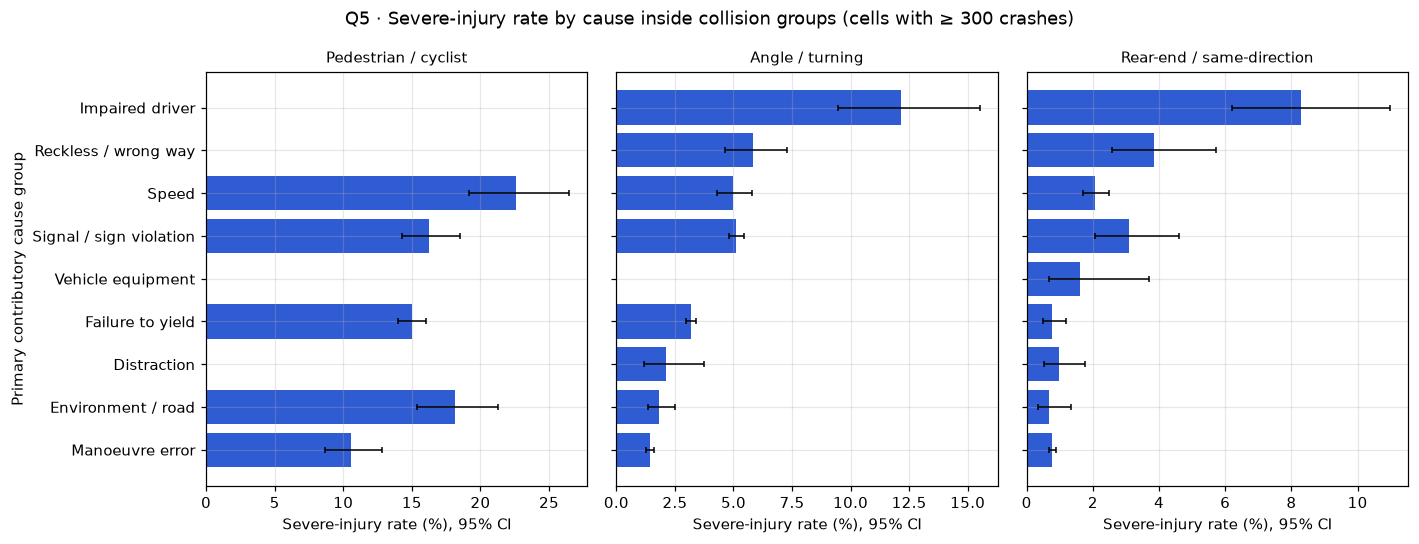

In [12]:
fig, axes = plt.subplots(1, len(subgroups), figsize=(13, 5), sharey=True)
order = [g for g in ranked["cause_group"]][::-1]
for ax, group in zip(axes, subgroups):
    part = within[within["collision_group"] == group].set_index("cause_group").reindex(order)
    ax.barh(part.index, part["rate_pct"], color="#2f5bd3")
    ax.errorbar(part["rate_pct"], part.index,
                xerr=[part["rate_pct"] - part["ci_low_pct"], part["ci_high_pct"] - part["rate_pct"]],
                fmt="none", ecolor="black", capsize=2, linewidth=1)
    ax.set_title(group, fontsize=10)
    ax.set_xlabel("Severe-injury rate (%), 95% CI")
axes[0].set_ylabel("Primary contributory cause group")
fig.suptitle(f"Q5 · Severe-injury rate by cause inside collision groups (cells with ≥ {MIN_CELL} crashes)")
fig.tight_layout()
save_figure(fig, "q5_fig3_within_collision_groups")

### 3.5 Robustness of the ranking (D6)

The standardised ranking is recomputed under three other reasonable choices:

1. **Full period** — all years 2013–2025 instead of 2018–2024.
2. **Broader outcome** — any reported injury (`has_injury`) instead of severe injury.
3. **Recorded causes only, finer labels** — the original cause labels with at least 500 crashes, to check that the grouping itself is not creating the result.

Agreement with the main ranking is measured with Spearman's rank correlation $\rho$ (1 = identical order).

In [13]:
def standardized_ranking(data, outcome="has_severe_injury", group_col="cause_group"):
    data = data[~data["cause_group"].isin(EXCLUDED_FROM_RANKING)]
    table = standardized_rate(data, group_col, ["collision_group"], outcome=outcome)
    return table.set_index(group_col)["std_rate_pct"]


main_rank = standardized_ranking(crashes)
variants = {
    "Main (2018-2024, severe)": main_rank,
    "Full period 2013-2025": standardized_ranking(all_years),
    "Any injury (2018-2024)": standardized_ranking(crashes, outcome="has_injury"),
}

robustness = pd.DataFrame(variants)
rank_table = robustness.rank(ascending=False).astype(int).sort_values("Main (2018-2024, severe)")
summary = pd.DataFrame({
    "spearman_rho_vs_main": [stats.spearmanr(robustness.iloc[:, 0], robustness[c]).statistic for c in robustness],
    "top_3": [", ".join(robustness[c].sort_values(ascending=False).index[:3]) for c in robustness],
}, index=robustness.columns)

rank_table.to_csv(OUTPUT_DIR / "q5_robustness_ranks.csv")
display(rank_table)
summary.round(3)

,"Main (2018-2024, severe)",Full period 2013-2025,Any injury (2018-2024)
cause_group,,,
Impaired driver,1,1,1
Reckless / wrong way,2,2,4
Speed,3,3,3
Signal / sign violation,4,4,2
Vehicle equipment,5,5,5
Failure to yield,6,6,6
Distraction,7,7,7
Environment / road,8,8,8
Manoeuvre error,9,9,9


,spearman_rho_vs_main,top_3
"Main (2018-2024, severe)",1.000,"Impaired driver, Reckless / wrong way, Speed"
Full period 2013-2025,1.000,"Impaired driver, Reckless / wrong way, Speed"
Any injury (2018-2024),0.933,"Impaired driver, Signal / sign violation, Speed"


In [14]:
MIN_LABEL = 500
recorded = crashes[~crashes["cause_group"].isin(EXCLUDED_FROM_RANKING)]
label_counts = recorded["prim_contributory_cause"].value_counts()
large_labels = recorded[recorded["prim_contributory_cause"].isin(label_counts[label_counts >= MIN_LABEL].index)]
report_rows(recorded, large_labels, f"Keep cause labels with >= {MIN_LABEL} crashes")

label_std = standardized_rate(large_labels, "prim_contributory_cause", ["collision_group"])
label_std["cause_group"] = label_std["prim_contributory_cause"].map(cause_lookup)
label_std = label_std.sort_values("std_rate_pct", ascending=False).reset_index(drop=True)
label_std.to_csv(OUTPUT_DIR / "q5_label_level_standardized.csv", index=False)
label_std.head(10).round(2)

Keep cause labels with >= 500 crashes: 125,658 -> 123,087 rows (2,571 removed)


,prim_contributory_cause,std_rate_pct,weight_coverage_pct,cause_group
0,UNDER THE INFLUENCE OF ALCOHOL/DRUGS (USE WHEN...,15.02,100.0,Impaired driver
1,PHYSICAL CONDITION OF DRIVER,11.50,100.0,Impaired driver
2,"OPERATING VEHICLE IN ERRATIC, RECKLESS, CARELE...",7.40,100.0,Reckless / wrong way
3,DISREGARDING TRAFFIC SIGNALS,6.28,100.0,Signal / sign violation
4,DISREGARDING OTHER TRAFFIC SIGNS,5.92,100.0,Signal / sign violation
5,EQUIPMENT - VEHICLE CONDITION,5.21,100.0,Vehicle equipment
6,FAILING TO REDUCE SPEED TO AVOID CRASH,5.10,100.0,Speed
7,DRIVING ON WRONG SIDE/WRONG WAY,3.96,100.0,Reckless / wrong way
8,DISREGARDING STOP SIGN,3.89,100.0,Signal / sign violation
9,FAILING TO YIELD RIGHT-OF-WAY,3.37,100.0,Failure to yield


---
## 4. Q6 — Intersection controls, lighting and severe injury

### 4.1 Preprocessing

1. Keep crashes the officer marked as **intersection-related** (`intersection_related_i == "Y"`).
2. Keep the three common control types: `TRAFFIC SIGNAL`, `STOP SIGN/FLASHER` and `NO CONTROLS`. The other 16 labels together cover about 2% of intersection crashes and are too small to compare one by one; `UNKNOWN` cannot be interpreted.
3. Derive a **lighting group** (D3) from `lighting_condition`: `DAYLIGHT` → *Daylight*; `DARKNESS` and `DARKNESS, LIGHTED ROAD` → *Dark*; `DUSK` and `DAWN` → *Dusk / dawn*; `UNKNOWN` is removed.

**Limitation to keep in mind:** in this Kaggle snapshot about 95% of 2018–2024 crashes are intersection-related. The snapshot is therefore not a random sample of all Chicago crashes, and the results describe crashes recorded at intersections only.

In [15]:
print(crashes["intersection_related_i"].value_counts(normalize=True).mul(100).round(1).to_string())

at_intersection = crashes[crashes["intersection_related_i"] == "Y"]
report_rows(crashes, at_intersection, "Keep intersection-related crashes")

DEVICES = {"TRAFFIC SIGNAL": "Traffic signal", "STOP SIGN/FLASHER": "Stop sign / flasher", "NO CONTROLS": "No controls"}
q6 = at_intersection[at_intersection["traffic_control_device"].isin(DEVICES)].copy()
report_rows(at_intersection, q6, "Keep signal, stop sign/flasher and no controls")

LIGHT_GROUPS = {
    "DAYLIGHT": "Daylight",
    "DARKNESS": "Dark",
    "DARKNESS, LIGHTED ROAD": "Dark",
    "DUSK": "Dusk / dawn",
    "DAWN": "Dusk / dawn",
}
before = q6
q6 = q6[q6["lighting_condition"].isin(LIGHT_GROUPS)].copy()
report_rows(before, q6, "Remove UNKNOWN lighting")

q6["device"] = pd.Categorical(q6["traffic_control_device"].map(DEVICES), categories=list(DEVICES.values()))
q6["light_group"] = pd.Categorical(q6["lighting_condition"].map(LIGHT_GROUPS),
                                   categories=["Daylight", "Dusk / dawn", "Dark"])
q6["device"].value_counts().to_frame("crashes")

intersection_related_i
Y    95.2
N     4.8
Keep intersection-related crashes: 181,051 -> 172,331 rows (8,720 removed)
Keep signal, stop sign/flasher and no controls: 172,331 -> 167,136 rows (5,195 removed)
Remove UNKNOWN lighting: 167,136 -> 164,557 rows (2,579 removed)


,crashes
device,
Traffic signal,101867
Stop sign / flasher,41097
No controls,21593


### 4.2 Severe-injury rate by device and lighting (D2, D5)

A pivot table of device × lighting group, each cell with its Wilson interval.

In [16]:
q6_device = rate_table(q6, "device")
q6_device_light = rate_table(q6, ["device", "light_group"])
q6_device_light.to_csv(OUTPUT_DIR / "q6_device_by_light.csv", index=False)

display(q6_device.round(2))
q6_device_light.pivot_table(index="device", columns="light_group", values="rate_pct", observed=True).round(2)

,device,crashes,severe,rate_pct,ci_low_pct,ci_high_pct
0,Traffic signal,101867,3629,3.56,3.45,3.68
1,Stop sign / flasher,41097,1279,3.11,2.95,3.28
2,No controls,21593,759,3.52,3.28,3.77


light_group,Daylight,Dusk / dawn,Dark
device,,,
Traffic signal,3.06,3.61,4.55
Stop sign / flasher,2.94,3.61,3.47
No controls,3.11,4.20,4.48


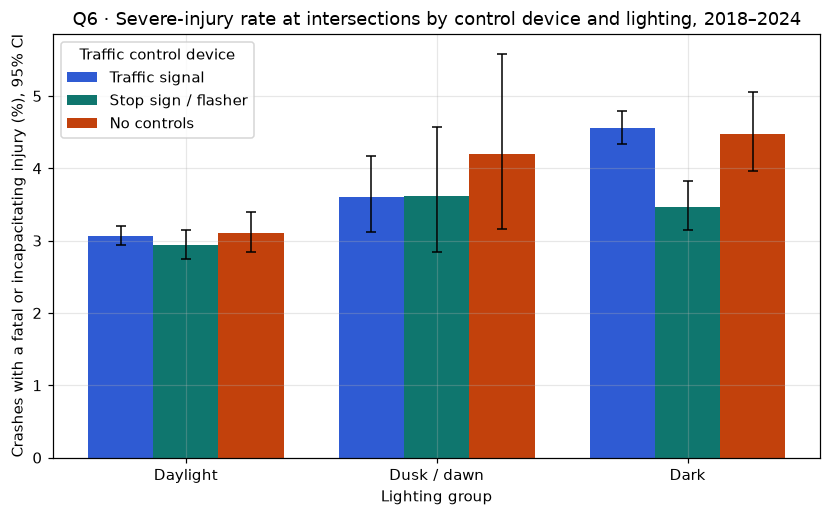

In [17]:
lights = list(q6["light_group"].cat.categories)
devices = list(q6["device"].cat.categories)
width = 0.26
x = np.arange(len(lights))
palette = {"Traffic signal": "#2f5bd3", "Stop sign / flasher": "#0f766e", "No controls": "#c2410c"}

fig, ax = plt.subplots(figsize=(9, 5))
for i, device in enumerate(devices):
    part = q6_device_light[q6_device_light["device"] == device].set_index("light_group").reindex(lights)
    ax.bar(x + (i - 1) * width, part["rate_pct"], width, label=device, color=palette[device])
    ax.errorbar(x + (i - 1) * width, part["rate_pct"],
                yerr=[part["rate_pct"] - part["ci_low_pct"], part["ci_high_pct"] - part["rate_pct"]],
                fmt="none", ecolor="black", capsize=3, linewidth=1)
ax.set_xticks(x, lights)
ax.set_title("Q6 · Severe-injury rate at intersections by control device and lighting, 2018–2024")
ax.set_xlabel("Lighting group")
ax.set_ylabel("Crashes with a fatal or incapacitating injury (%), 95% CI")
ax.legend(title="Traffic control device")
save_figure(fig, "q6_fig1_device_by_light")

### 4.3 Hour-of-day profile (D2)

The severe-injury rate is pivoted to hour × device. Hourly cells are noisy, so a **centred 3-hour rolling mean** is drawn on top. The hour axis wraps around midnight, so the series is padded with the last hour before 0:00 and the first hour after 23:00 before rolling.

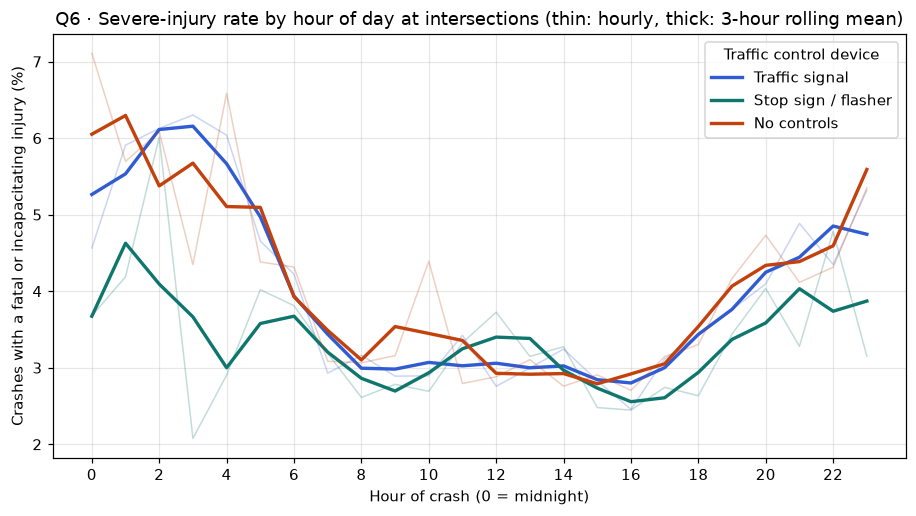

Smallest hourly cell: 167 crashes


In [18]:
hourly = q6.pivot_table(index="crash_hour", columns="device", values="has_severe_injury",
                        aggfunc="mean", observed=True) * 100
hourly_counts = q6.pivot_table(index="crash_hour", columns="device", values="has_severe_injury",
                               aggfunc="size", observed=True)

padded = pd.concat([hourly.iloc[[-1]], hourly, hourly.iloc[[0]]])
smoothed = padded.rolling(3, center=True).mean().iloc[1:-1]
smoothed.index = hourly.index

fig, ax = plt.subplots(figsize=(10, 5))
for device in devices:
    ax.plot(hourly.index, hourly[device], color=palette[device], alpha=0.25, linewidth=1)
    ax.plot(smoothed.index, smoothed[device], color=palette[device], linewidth=2.2, label=device)
ax.set_xticks(range(0, 24, 2))
ax.set_title("Q6 · Severe-injury rate by hour of day at intersections (thin: hourly, thick: 3-hour rolling mean)")
ax.set_xlabel("Hour of crash (0 = midnight)")
ax.set_ylabel("Crashes with a fatal or incapacitating injury (%)")
ax.legend(title="Traffic control device")
save_figure(fig, "q6_fig2_hour_profile")

print("Smallest hourly cell:", int(hourly_counts.min().min()), "crashes")

### 4.4 Controlling for collision type and lighting (D4, D5)

Different intersections see different crashes: a signalised junction on an arterial road has more pedestrians and more angle crashes than a quiet stop-sign corner. Two methods are used:

1. **Direct standardisation** of each device's rate to the collision-group × lighting-group mix of all intersection crashes in this sample.
2. **Mantel–Haenszel** pooled odds ratio of a severe injury for *traffic signal vs no controls* and *stop sign vs no controls*, stratified by collision group × lighting group. The Mantel–Haenszel test checks whether the pooled odds ratio differs from 1, and the Breslow–Day test checks whether the odds ratio is similar across strata. Strata in which one of the two devices has no crashes are skipped.

In [19]:
mix = (pd.crosstab(q6["device"], q6["collision_group"], normalize="index") * 100).round(1)
display(mix)

q6_std = standardized_rate(q6, "device", ["collision_group", "light_group"])
q6_compare = q6_device[["device", "crashes", "rate_pct", "ci_low_pct", "ci_high_pct"]].merge(q6_std, on="device")
q6_compare.to_csv(OUTPUT_DIR / "q6_crude_vs_standardized.csv", index=False)
q6_compare.round(2)

collision_group,Angle / turning,Head-on / opposite-direction,Pedestrian / cyclist,Rear-end / same-direction,Single vehicle / object
device,,,,,
Traffic signal,53.2,1.7,6.9,35.0,3.2
Stop sign / flasher,73.4,1.3,6.8,13.8,4.7
No controls,55.6,2.2,7.3,24.4,10.6


,device,crashes,rate_pct,ci_low_pct,ci_high_pct,std_rate_pct,weight_coverage_pct
0,Traffic signal,101867,3.56,3.45,3.68,3.72,100.0
1,Stop sign / flasher,41097,3.11,2.95,3.28,2.91,100.0
2,No controls,21593,3.52,3.28,3.77,3.42,100.0


In [20]:
def mantel_haenszel(data, exposed, reference, strata=("collision_group", "light_group")):
    """Pooled odds ratio of a severe injury for one device versus a reference device."""
    pair = data[data["device"].isin([exposed, reference])]
    tables = []
    for _, stratum in pair.groupby(list(strata), observed=True):
        t = pd.crosstab(stratum["device"] == exposed, stratum["has_severe_injury"]).reindex(
            index=[True, False], columns=[True, False], fill_value=0
        )
        if (t.sum(axis=1) > 0).all():
            tables.append(t.to_numpy())
    st = StratifiedTable(tables)
    low, high = st.oddsratio_pooled_confint()
    return {
        "comparison": f"{exposed} vs {reference}",
        "strata_used": len(tables),
        "crude_or": (lambda t: (t[0, 0] * t[1, 1]) / (t[0, 1] * t[1, 0]))(sum(tables)),
        "mh_or": st.oddsratio_pooled,
        "ci_low": low,
        "ci_high": high,
        "mh_test_p": st.test_null_odds().pvalue,
        "breslow_day_p": st.test_equal_odds().pvalue,
    }


q6_mh = pd.DataFrame([
    mantel_haenszel(q6, "Traffic signal", "No controls"),
    mantel_haenszel(q6, "Stop sign / flasher", "No controls"),
    mantel_haenszel(q6, "Traffic signal", "Stop sign / flasher"),
])
q6_mh.to_csv(OUTPUT_DIR / "q6_mantel_haenszel.csv", index=False)
q6_mh.round(4)

,comparison,strata_used,crude_or,mh_or,ci_low,ci_high,mh_test_p,breslow_day_p
0,Traffic signal vs No controls,15,1.0140,1.0982,1.0116,1.1921,0.0252,0.0000
1,Stop sign / flasher vs No controls,15,0.8817,0.8546,0.7774,0.9396,0.0012,0.0433
2,Traffic signal vs Stop sign / flasher,15,1.1500,1.3120,1.2277,1.4020,0.0000,0.0405


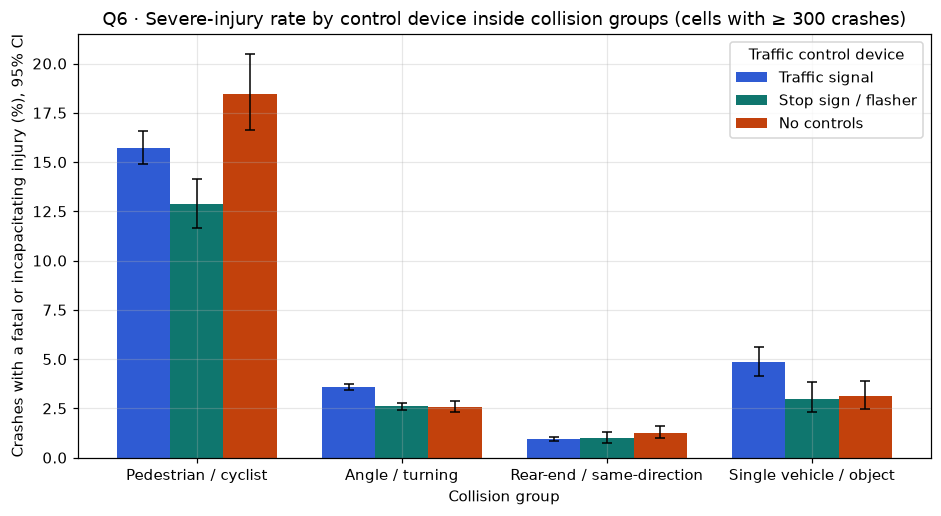

device,Traffic signal,Stop sign / flasher,No controls
collision_group,,,
Angle / turning,3.58,2.60,2.58
Head-on / opposite-direction,4.80,3.82,4.48
Pedestrian / cyclist,15.73,12.86,18.48
Rear-end / same-direction,0.96,0.99,1.25
Single vehicle / object,4.84,2.96,3.11


In [21]:
q6_within = rate_table(q6, ["collision_group", "device"])
q6_within = q6_within[q6_within["crashes"] >= 300]
groups = ["Pedestrian / cyclist", "Angle / turning", "Rear-end / same-direction", "Single vehicle / object"]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(groups))
for i, device in enumerate(devices):
    part = q6_within[q6_within["device"] == device].set_index("collision_group").reindex(groups)
    ax.bar(x + (i - 1) * width, part["rate_pct"], width, label=device, color=palette[device])
    ax.errorbar(x + (i - 1) * width, part["rate_pct"],
                yerr=[part["rate_pct"] - part["ci_low_pct"], part["ci_high_pct"] - part["rate_pct"]],
                fmt="none", ecolor="black", capsize=3, linewidth=1)
ax.set_xticks(x, groups)
ax.set_title("Q6 · Severe-injury rate by control device inside collision groups (cells with ≥ 300 crashes)")
ax.set_xlabel("Collision group")
ax.set_ylabel("Crashes with a fatal or incapacitating injury (%), 95% CI")
ax.legend(title="Traffic control device")
save_figure(fig, "q6_fig3_device_within_collision")

q6_within.pivot_table(index="collision_group", columns="device", values="rate_pct", observed=True).round(2)

---
## 5. Answers

### Q5 — Which cause groups have an unusually high severe-injury rate?

**Direct answer.** Out of 181,051 crashes in 2018–2024, 6,146 (3.39%) had a fatal or incapacitating injury. Among the nine recorded cause groups, the three highest after standardising to the collision-type mix of all crashes are:

| Rank | Cause group | Crude rate | Standardised rate | Risk ratio vs manoeuvre error (95% CI) |
|---:|---|---:|---:|---:|
| 1 | Impaired driver | 10.73% | 12.64% | 8.47 (7.17–9.99) |
| 2 | Reckless / wrong way | 6.98% | 6.34% | 5.51 (4.70–6.46) |
| 3 | Speed | 4.50% | 5.47% | 3.55 (3.14–4.01) |

Ordinary manoeuvre errors (following too closely, improper turning or lane use) are the lowest at 1.27%. At label level, driving under the influence of alcohol or drugs reaches 15.02% after standardisation, about 4.4 times the average crash.

**Accounting for who was hit changes the middle of the ranking, not the top.**

- *Failure to yield* looks dangerous in the crude ranking (4.49%), but 12.3% of these crashes involve a pedestrian or cyclist, against 1.8% for manoeuvre errors. After standardisation it falls to 3.45% and from rank 5 to 6.
- *Speed* moves the other way, from 4.50% to 5.47% (rank 4 to 3). Half of speed-related crashes are rear-end collisions, the least severe collision type, so the crude rate understates how severe a speed-related crash is *for a given type of collision*.
- Inside pedestrian and cyclist crashes, speed is the most severe recorded cause (22.62% against 10.57% for manoeuvre errors). Inside angle and turning crashes, impaired drivers lead (12.17%).

**Robustness.** The standardised order is identical when all years 2013–2025 are used (Spearman ρ = 1.00). With *any* injury as the outcome the order stays very similar (ρ = 0.93): impaired driving and speed stay in the top three, while signal and sign violations move up to second, meaning they produce many injuries but proportionally fewer severe ones.

**Practical meaning.** Impairment, reckless driving and speed are where enforcement is most likely to prevent the worst outcomes per crash. Failure to yield is still the second largest cause group by volume (37,544 crashes) and remains a priority because of its size, but its high crude severity is mostly about pedestrians, which points to crossing design and driver awareness of pedestrians rather than general enforcement.

**Surprise.** Speed is *under*-estimated by the crude comparison, because speed-related crashes are often rear-end collisions.

**Limitations.** The cause is the officer's judgement at the scene, and 30.6% of crashes have no determined cause, which may hide differences between groups. Impairment is probably under-recorded when no arrest is made. Rates describe what happens *given* a crash; they do not say how often each behaviour leads to a crash.

### Q6 — Does the intersection control device relate to severe injury?

**Direct answer.** At 164,557 intersection crashes with a signal, stop sign/flasher or no controls and known lighting:

| Device | Crashes | Crude rate (95% CI) | Standardised rate |
|---|---:|---:|---:|
| Traffic signal | 101,867 | 3.56% (3.45–3.68) | 3.72% |
| Stop sign / flasher | 41,097 | 3.11% (2.95–3.28) | 2.91% |
| No controls | 21,593 | 3.52% (3.28–3.77) | 3.42% |

After stratifying by collision group and lighting, the Mantel–Haenszel odds of a severe injury are **15% lower at stop signs than at intersections without controls** (OR 0.85, 95% CI 0.78–0.94, p = 0.001) and **31% higher at traffic signals than at stop signs** (OR 1.31, 1.23–1.40, p < 0.001). Signals versus no controls differ only slightly (OR 1.10, 1.01–1.19, p = 0.025).

**The answer depends on the collision type.** The Breslow–Day test shows that the odds ratio is not the same across strata (p < 0.001 for signal vs no controls):

- In **angle and turning** crashes, signals have the highest rate (3.58% against 2.60% for stop signs and 2.58% for no controls), which fits faster traffic on signalised arterial roads.
- In **pedestrian and cyclist** crashes, intersections **without controls** are the most severe (18.48% against 15.73% at signals and 12.86% at stop signs).

**Lighting and time of day.** Darkness raises the severe-injury rate for every device. The largest gap is at traffic signals, from 3.06% in daylight to 4.55% in the dark. The 3-hour rolling profile is lowest in mid-afternoon (2.6–2.8% around 15:00–16:00) and highest around 1:00–3:00 (6.2% at signals and 6.3% with no controls, but 4.6% at stop signs).

**Practical meaning.** Stop-controlled intersections are associated with fewer severe outcomes even after accounting for crash type and lighting. For pedestrians and cyclists, uncontrolled intersections are the most dangerous place to be hit, which supports adding crossing controls there. At signals, the problem is concentrated in angle and turning crashes at night, which points to speed management and lighting on signalised corridors.

**Surprise.** Signals, usually seen as the safest control, have the highest standardised severe-injury rate. A likely reason is that signals are installed on busier, faster roads, which this dataset cannot measure.

**Limitations.** The data have no traffic volume, speed limit or road size, so the device cannot be separated from the kind of road it is installed on; these are associations, not causal effects. About 95% of crashes in this Kaggle snapshot are marked intersection-related, so it is not a representative sample of all Chicago crashes, and non-intersection crashes cannot be compared.